<a href="https://colab.research.google.com/github/syedh99/SMS_Spam_Proj/blob/main/SMS_Spam_Checker.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SMS Spam Detection: Prompting, Label Scoring, and Robustness

**CSI-4130/5130 — Artificial Intelligence Semester Project**

## Project Overview

This project evaluates several methods for identifying spam SMS messages.

We compare traditional machine learning against Google's FLAN-T5 language model and investigate how prompt engineering, classification methods, and text obfuscation affect performance.

### Experiments

| Experiment | Description |
|---|---|
| E01 | Original TF-IDF baseline and FLAN-T5 prompting |
| E02 | Improved zero-shot and few-shot prompting |
| E03 | Candidate-label scoring and character-level TF-IDF |
| E04 | Modern SMS evaluation, including political outreach |
| E05 | Final evaluation on previously unseen messages |

### Research Questions

1. How does traditional machine learning compare with an instruction-tuned language model?
2. Does improving the prompt improve spam classification?
3. Does candidate-label scoring outperform text generation?
4. How does character-level TF-IDF handle disguised spam keywords?
5. Do the experimental improvements generalize to unseen messages?

### Technologies

- Python and Google Colab
- PyTorch
- Hugging Face Transformers
- Google FLAN-T5-base
- Scikit-learn
- UCI SMS Spam Collection

**Note:** The project uses pretrained language models without fine-tuning.

All experiments are saved into a single results package at the end.

## 0. How to Run This Notebook

1. Open Google Colab.
2. Select Runtime → Change runtime type → T4 GPU.
3. Run the cells sequentially, starting at the top.
4. The UCI SMS dataset and FLAN-T5 model will download automatically.
5. All experiments will save their results to a common folder.
6. The final export cell generates and downloads one ZIP file.

### Evaluation Strategy

- Development sample: 240 messages for E01–E03.
- Final evaluation: 300 different messages for E05.
- E04: 12 synthetic modern SMS examples for qualitative analysis.

The final E05 messages are not used to modify or select prompts.

Keep the final test set independent to avoid overfitting the evaluation.

## 1. Environment and Configuration

This notebook is designed for Google Colab with an NVIDIA Tesla T4 GPU.

Required libraries:

- PyTorch
- Transformers
- SentencePiece
- Scikit-learn
- Pandas
- NumPy
- Matplotlib

A fixed random seed is used to make the experiments reproducible.

In [1]:
%pip -q install "sentencepiece>=0.2.0" "scikit-learn>=1.6" "safetensors>=0.4"

In [2]:
import io
import json
import random
import re
import shutil
import sys
import time
import urllib.request
import zipfile

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from IPython.display import display

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

from transformers import AutoModelForSeq2SeqLM, AutoTokenizer


# ==================================================
# PROJECT CONFIGURATION
# ==================================================

SEED = 42

MODEL_NAME = "google/flan-t5-base"

# Original development evaluation size
DEV_SAMPLES = 240

# E05: final unseen messages
# Change to None to use all remaining 1,050 messages
FINAL_SAMPLES = 300

BATCH_SIZE = 12

MAX_INPUT_TOKENS = 384
MAX_OUTPUT_TOKENS = 8


# ==================================================
# OUTPUT DIRECTORY
# ==================================================

OUTPUT_DIR = Path("sms_spam_project_results")

# Start each full run with a clean output folder
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

OUTPUT_DIR.mkdir(parents=True)


# ==================================================
# REPRODUCIBILITY
# ==================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ==================================================
# GPU CONFIGURATION
# ==================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not enabled. LLM inference will be slower.")

print("Development samples:", DEV_SAMPLES)
print("Final evaluation samples:", FINAL_SAMPLES or "all remaining")

Python: 3.13.16
PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4
Development samples: 240
Final evaluation samples: 300


## 2. Dataset Preparation

We use the UCI SMS Spam Collection dataset.

Source:
https://archive.ics.uci.edu/dataset/228/sms+spam+collection

### Labels

- ham: Legitimate SMS messages
- spam: Unwanted or fraudulent SMS messages

### Preprocessing

1. Download the dataset.
2. Remove duplicate SMS text.
3. Perform a stratified 75% training / 25% holdout split.
4. Select 240 development messages.
5. Reserve the remaining holdout messages for independent final evaluation.

The same development messages are used across E01–E03.

E05 uses a separate subset that does not overlap with training or development.

In [3]:
DATA_URLS = [
    "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip",
    "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip",
]


def fetch_sms_collection():

    last_error = None

    for url in DATA_URLS:

        try:
            with urllib.request.urlopen(
                url, timeout=40
            ) as response:
                data = response.read()

            with zipfile.ZipFile(io.BytesIO(data)) as zf:

                matches = [
                    p for p in zf.namelist()
                    if p.split("/")[-1] == "SMSSpamCollection"
                ]

                if not matches:
                    raise ValueError("Dataset file missing")

                content = zf.read(
                    matches[0]
                ).decode("latin-1")

            rows = []

            for line in content.splitlines():

                label, tab, message = line.partition("\t")

                if (
                    tab
                    and label in ("ham", "spam")
                    and message.strip()
                ):
                    rows.append((label, message.strip()))

            if len(rows) < 5000:
                raise ValueError("Unexpected dataset size")

            print("Downloaded:", url)

            return pd.DataFrame(
                rows,
                columns=["label", "text"]
            )

        except Exception as exc:
            print("Download source failed:", exc)
            last_error = exc

    raise RuntimeError(
        "Unable to download SMS dataset"
    ) from last_error


# ==================================================
# LOAD AND CLEAN DATA
# ==================================================

raw_df = fetch_sms_collection()

data_df = raw_df.drop_duplicates(
    subset="text"
).reset_index(drop=True)


# ==================================================
# TRAIN / TEST SPLIT
# ==================================================

train_df, test_df = train_test_split(
    data_df,
    test_size=0.25,
    random_state=SEED,
    stratify=data_df["label"]
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)


# ==================================================
# DEVELOPMENT / FINAL HOLDOUT SPLIT
# ==================================================

assert 0 < DEV_SAMPLES < len(test_df)

dev_df, e05_pool = train_test_split(
    test_df,
    train_size=DEV_SAMPLES,
    random_state=SEED,
    stratify=test_df["label"]
)

dev_df = dev_df.reset_index(drop=True)
e05_pool = e05_pool.reset_index(drop=True)


# E05 independent evaluation sample
if FINAL_SAMPLES is None:

    final_df = e05_pool.copy()

else:

    assert 0 < FINAL_SAMPLES <= len(e05_pool)

    if FINAL_SAMPLES == len(e05_pool):

        final_df = e05_pool.copy()

    else:

        final_df, _ = train_test_split(
            e05_pool,
            train_size=FINAL_SAMPLES,
            random_state=SEED + 1,
            stratify=e05_pool["label"]
        )

final_df = final_df.reset_index(drop=True)


# ==================================================
# VERIFY NO DATA OVERLAP
# ==================================================

assert set(train_df.text).isdisjoint(set(dev_df.text))
assert set(train_df.text).isdisjoint(set(final_df.text))
assert set(dev_df.text).isdisjoint(set(final_df.text))


print("\nDATASET SUMMARY")

print("Original records:", len(raw_df))
print("Unique records:", len(data_df))

print("Training:", len(train_df))
print("Full holdout:", len(test_df))

print("Development:", len(dev_df))
print("Remaining E05 pool:", len(e05_pool))
print("Final evaluation:", len(final_df))

print("\nDevelopment class distribution:")
display(dev_df["label"].value_counts())

print("\nSample messages:")
display(train_df.head())

Downloaded: https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip

DATASET SUMMARY
Original records: 5574
Unique records: 5160
Training: 3870
Full holdout: 1290
Development: 240
Remaining E05 pool: 1050
Final evaluation: 300

Development class distribution:


,count
label,
ham,210
spam,30



Sample messages:


,label,text
0,ham,Stop knowing me so well!
1,ham,Yup he msg me: is tat yijue? Then i tot it's m...
2,ham,"We are at grandmas. Oh dear, u still ill? I fe..."
3,ham,K...k...when will you give treat?
4,ham,Carlos says we can pick up from him later so y...


## 3. SMS Keyword Obfuscation

Spam messages frequently disguise keywords to avoid detection.

Examples:

- free → fr33
- win → w1n
- prize → pr1ze
- claim → cl@im
- urgent → urg3nt

We apply deterministic character substitutions to messages.

Each classifier is evaluated on:

1. Original SMS messages
2. Obfuscated SMS messages

We also analyze only the messages that were actually modified.

In [4]:
OBFUSCATIONS = {
    "free": "fr33",
    "win": "w1n",
    "winner": "w1nn3r",
    "prize": "pr1ze",
    "urgent": "urg3nt",
    "claim": "cl@im",
    "cash": "ca$h",
    "call": "c@ll",
    "reply": "r3ply",
    "offer": "0ffer",
    "bonus": "b0nus",
    "credit": "cr3dit"
}


OBFUSCATION_RE = re.compile(
    r"\b(?:"
    + "|".join(
        map(
            re.escape,
            sorted(OBFUSCATIONS, key=len, reverse=True)
        )
    )
    + r")\b",
    flags=re.IGNORECASE
)


def obfuscate(text):

    return OBFUSCATION_RE.sub(
        lambda match: OBFUSCATIONS[
            match.group(0).lower()
        ],
        text
    )


def attach_obfuscation(frame):

    result = frame.copy().reset_index(drop=True)

    result["obfuscated_text"] = (
        result["text"].map(obfuscate)
    )

    result["was_changed"] = (
        result["obfuscated_text"] != result["text"]
    )

    return result


# Apply transformations
dev_df = attach_obfuscation(dev_df)
final_df = attach_obfuscation(final_df)


print(
    "Development messages modified:",
    int(dev_df.was_changed.sum())
)

print(
    "Final evaluation messages modified:",
    int(final_df.was_changed.sum())
)


display(
    dev_df.loc[
        dev_df["was_changed"],
        ["label", "text", "obfuscated_text"]
    ].head()
)

Development messages modified: 48
Final evaluation messages modified: 38


,label,text,obfuscated_text
13,ham,This is wishing you a great day. Moji told me ...,This is wishing you a great day. Moji told me ...
18,spam,74355 XMAS iscoming & ur awarded either Â£500 ...,74355 XMAS iscoming & ur awarded either Â£500 ...
20,spam,FREE GAME. Get Rayman Golf 4 FREE from the O2 ...,fr33 GAME. Get Rayman Golf 4 fr33 from the O2 ...
21,spam,We tried to contact you re our offer of New Vi...,We tried to contact you re our 0ffer of New Vi...
28,ham,"Sorry, in meeting I'll call you later","Sorry, in meeting I'll c@ll you later"


## 4. Traditional Machine Learning Baselines

We compare two representations of SMS text.

### Word-Level TF-IDF

Transforms words and word pairs into numerical features.

This is the original E01 baseline.

### Character-Level TF-IDF

Transforms character sequences into numerical features.

This is the E03 improvement, designed to capture patterns
that may remain useful when words contain misspellings
or character substitutions.

Both representations use Logistic Regression.

Both models are trained only on the training dataset.

In [5]:
# ==================================================
# WORD-LEVEL TF-IDF
# ==================================================

word_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1500,
            class_weight="balanced",
            random_state=SEED
        )
    )
])


# ==================================================
# CHARACTER-LEVEL TF-IDF
# ==================================================

char_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(3, 5),
            min_df=2,
            max_features=60000,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1500,
            class_weight="balanced",
            random_state=SEED
        )
    )
])


# ==================================================
# TRAIN MODELS
# ==================================================

word_model.fit(
    train_df["text"],
    train_df["label"]
)

char_model.fit(
    train_df["text"],
    train_df["label"]
)


print("Both traditional ML models trained successfully.")

Both traditional ML models trained successfully.


## 5. FLAN-T5 and Prompt Engineering

We use Google FLAN-T5-base, an instruction-tuned
encoder-decoder language model.

We preserve both prompting configurations separately:

### E01: Original Prompts
- Original spam/ham instructions
- Few-shot examples sampled from training data

### E02: Improved Prompts
- More explicit spam/ham definitions
- Four handcrafted few-shot examples

Both experiments use the same pretrained model.

No model weights are fine-tuned.

Note: E02 changes both instructions and example selection.

In [6]:
# ==================================================
# LOAD FLAN-T5
# ==================================================

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_NAME,
    use_safetensors=True
)

model = model.to(DEVICE).eval()

print("Loaded:", MODEL_NAME)


# ==================================================
# E01 - ORIGINAL PROMPT CONFIGURATION
# ==================================================

E01_EXAMPLE_ROWS = []

for label in ("ham", "spam"):

    eligible = train_df[
        (train_df.label == label)
        & train_df.text.str.len().between(15, 110)
    ]

    selected = eligible.sample(
        n=2,
        random_state=SEED
    )

    for text in selected.text:

        E01_EXAMPLE_ROWS.append((
            re.sub(r"\s+", " ", text).strip(),
            label
        ))


E01_EXAMPLE_BLOCK = "\n\n".join(
    f"SMS: {text}\nLabel: {label}"
    for text, label in E01_EXAMPLE_ROWS
)


E01_INSTRUCTIONS = (
    "Classify the SMS message as spam or ham. "
    "Spam means an unsolicited commercial message, "
    "a scam, or a deceptive prize or cash offer. "
    "Ham means a legitimate ordinary message. "
    "Respond with exactly one lowercase word: "
    "spam or ham."
)


def build_prompt_e01(message, strategy):

    if strategy == "Zero-shot":

        return (
            f"{E01_INSTRUCTIONS}\n\n"
            f"SMS: {message}\n"
            "Label:"
        )

    if strategy == "Few-shot":

        return (
            f"{E01_INSTRUCTIONS}\n\n"
            f"Examples:\n"
            f"{E01_EXAMPLE_BLOCK}\n\n"
            f"SMS: {message}\n"
            "Label:"
        )

    raise ValueError(strategy)


# ==================================================
# E02 - IMPROVED PROMPT CONFIGURATION
# ==================================================

E02_INSTRUCTIONS = (
    "You are classifying SMS text messages.\n"
    "Spam: Unwanted advertisements, scams, fake prizes, "
    "and unsolicited promotional messages.\n"
    "Ham: Normal personal messages, conversations, "
    "appointments, and routine communication.\n"
    "Respond with only one word: ham or spam."
)


E02_EXAMPLES = [
    ("Are we still meeting for dinner tonight?", "ham"),
    ("Hey, I'll call you when I get home.", "ham"),
    ("WIN a FREE CASH PRIZE! Claim it now!", "spam"),
    ("Congratulations! Click here to collect your reward.", "spam")
]


def build_prompt_e02(message, strategy):

    prompt = E02_INSTRUCTIONS + "\n\n"

    if strategy == "Few-shot":

        for text, label in E02_EXAMPLES:

            prompt += (
                f"SMS: {text}\n"
                f"Label: {label}\n\n"
            )

    elif strategy != "Zero-shot":
        raise ValueError(strategy)

    return prompt + f"SMS: {message}\nLabel:"


# ==================================================
# VALIDATION
# ==================================================

assert "Examples:" in build_prompt_e01(
    "hello", "Few-shot"
)

assert "WIN a FREE CASH PRIZE" in build_prompt_e02(
    "hello", "Few-shot"
)

assert "WIN a FREE CASH PRIZE" not in build_prompt_e02(
    "hello", "Zero-shot"
)

print("E01 and E02 prompting configurations ready.")

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Loaded: google/flan-t5-base
E01 and E02 prompting configurations ready.


## 6. Shared Classification and Evaluation Framework

To simplify the notebook, every model uses the same
prediction and evaluation framework.

### Classification Methods

1. Traditional Logistic Regression
2. FLAN-T5 text generation
3. FLAN-T5 candidate-label scoring

### Evaluation Metrics

- Accuracy
- Spam precision
- Spam recall
- Spam F1-score
- Inference time
- Invalid output count

### Inference Optimization

The models first classify the original messages.

For obfuscated evaluation, only messages that were
actually modified require additional inference.

Unmodified messages reuse their original predictions.

Therefore, obfuscated inference times represent
incremental processing time, not full-dataset runtime.

In [7]:
# ==================================================
# OUTPUT PARSING
# ==================================================

def parse_label(text):

    normalized = re.sub(
        r"[^a-z]",
        "",
        str(text).lower().strip()
    )

    if normalized in {"ham", "spam"}:
        return normalized

    return "invalid"


# ==================================================
# FLAN-T5 TEXT GENERATION
# ==================================================

@torch.inference_mode()
def predict_generated(messages, prompt_fn, strategy):

    messages = list(messages)

    raw_outputs = []
    start = time.perf_counter()

    for pos in range(0, len(messages), BATCH_SIZE):

        batch = messages[pos:pos + BATCH_SIZE]

        prompts = [
            prompt_fn(str(m), strategy)
            for m in batch
        ]

        inputs = tokenizer(
            prompts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_INPUT_TOKENS
        ).to(DEVICE)

        generated = model.generate(
            **inputs,
            do_sample=False,
            max_new_tokens=MAX_OUTPUT_TOKENS
        )

        decoded = tokenizer.batch_decode(
            generated,
            skip_special_tokens=True
        )

        raw_outputs.extend(decoded)

    predictions = [
        parse_label(x)
        for x in raw_outputs
    ]

    elapsed = time.perf_counter() - start

    return predictions, raw_outputs, elapsed


# ==================================================
# FLAN-T5 CANDIDATE-LABEL SCORING
# ==================================================

@torch.inference_mode()
def predict_label_scoring(messages):

    messages = list(messages)

    options = ["ham", "spam"]

    option_ids = tokenizer(
        options,
        padding=True,
        return_tensors="pt"
    )["input_ids"].to(DEVICE)

    predictions = []

    start = time.perf_counter()

    for pos in range(0, len(messages), BATCH_SIZE):

        batch = messages[pos:pos + BATCH_SIZE]

        prompts = [
            build_prompt_e02(str(m), "Zero-shot")
            for m in batch
        ]

        inputs = tokenizer(
            prompts,
            padding=True,
            truncation=True,
            max_length=MAX_INPUT_TOKENS,
            return_tensors="pt"
        ).to(DEVICE)

        # Repeat each SMS for both candidate labels
        paired_ids = inputs["input_ids"].repeat_interleave(
            2,
            dim=0
        )

        paired_mask = inputs["attention_mask"].repeat_interleave(
            2,
            dim=0
        )

        labels = option_ids.repeat(
            len(batch),
            1
        )

        labels[labels == tokenizer.pad_token_id] = -100

        # Score each candidate output
        result = model(
            input_ids=paired_ids,
            attention_mask=paired_mask,
            labels=labels
        )

        log_probs = torch.log_softmax(
            result.logits.float(),
            dim=-1
        )

        valid = labels.ne(-100)

        token_scores = log_probs.gather(
            -1,
            labels.clamp_min(0).unsqueeze(-1)
        ).squeeze(-1)

        scores = token_scores.masked_fill(
            ~valid,
            0
        ).sum(dim=1).reshape(len(batch), 2)

        best_indices = scores.argmax(
            dim=1
        ).tolist()

        predictions.extend(
            options[int(i)]
            for i in best_indices
        )

    elapsed = time.perf_counter() - start

    return (
        predictions,
        [""] * len(predictions),
        elapsed
    )


# ==================================================
# TRADITIONAL MACHINE LEARNING
# ==================================================

def predict_classical(messages, classifier):

    start = time.perf_counter()

    predictions = classifier.predict(
        list(messages)
    ).tolist()

    elapsed = time.perf_counter() - start

    return (
        predictions,
        [""] * len(predictions),
        elapsed
    )


# ==================================================
# ORIGINAL / OBFUSCATED PREDICTIONS
# ==================================================

def paired_predict(frame, predict_fn):

    original, original_raw, original_seconds = (
        predict_fn(frame.text.tolist())
    )

    modified = list(original)
    modified_raw = list(original_raw)

    changed_positions = np.flatnonzero(
        frame.was_changed.to_numpy()
    )

    incremental_seconds = 0.0

    if len(changed_positions):

        changed_texts = frame.iloc[
            changed_positions
        ].obfuscated_text.tolist()

        changed_pred, changed_raw, incremental_seconds = (
            predict_fn(changed_texts)
        )

        for index, prediction, raw in zip(
            changed_positions,
            changed_pred,
            changed_raw
        ):

            modified[index] = prediction
            modified_raw[index] = raw

    return {
        "Original": (
            original,
            original_raw,
            original_seconds
        ),
        "Obfuscated": (
            modified,
            modified_raw,
            incremental_seconds
        )
    }


# ==================================================
# METRIC CALCULATION
# ==================================================

def metric_row(
    y_true,
    y_pred,
    method,
    scenario,
    experiment,
    seconds,
    changed_count
):

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=["spam"],
            zero_division=0
        )
    )

    return {
        "experiment": experiment,
        "method": method,
        "scenario": scenario,
        "n": len(y_true),
        "changed_in_full_set": changed_count,
        "accuracy": accuracy_score(y_true, y_pred),
        "spam_precision": float(precision[0]),
        "spam_recall": float(recall[0]),
        "spam_f1": float(f1[0]),
        "invalid_outputs": sum(
            p == "invalid"
            for p in y_pred
        ),
        "inference_seconds": round(float(seconds), 3)
    }


# ==================================================
# EVALUATE MULTIPLE MODELS
# ==================================================

def evaluate_methods(frame, method_specs):

    full_rows = []
    changed_rows = []

    details = frame[
        [
            "label",
            "text",
            "obfuscated_text",
            "was_changed"
        ]
    ].copy()

    changed_idx = np.flatnonzero(
        frame.was_changed.to_numpy()
    )

    truth = frame.label.tolist()

    for experiment, method, fn in method_specs:

        print("Evaluating:", method)

        outputs = paired_predict(frame, fn)

        for scenario, (pred, raw, seconds) in outputs.items():

            # Full sample metrics
            full_rows.append(
                metric_row(
                    truth,
                    pred,
                    method,
                    scenario,
                    experiment,
                    seconds,
                    len(changed_idx)
                )
            )

            # Changed-only metrics
            if len(changed_idx):

                changed_rows.append(
                    metric_row(
                        [truth[i] for i in changed_idx],
                        [pred[i] for i in changed_idx],
                        method,
                        scenario,
                        experiment,
                        seconds,
                        len(changed_idx)
                    )
                )

            # Individual predictions
            safe = re.sub(
                r"[^a-zA-Z0-9]+",
                "_",
                method
            ).strip("_")

            details[f"{safe}_{scenario}"] = pred

            # Preserve original text-generation outputs
            if (
                method.startswith("E01 ")
                or method.startswith("E02 ")
            ):

                details[f"raw_{safe}_{scenario}"] = raw

    return (
        pd.DataFrame(full_rows),
        pd.DataFrame(changed_rows),
        details
    )


# ==================================================
# SAVE EXPERIMENT RESULTS
# ==================================================

def save_experiment(
    tag,
    metrics,
    changed,
    predictions
):

    metrics.to_csv(
        OUTPUT_DIR / f"{tag}_metrics.csv",
        index=False
    )

    changed.to_csv(
        OUTPUT_DIR / f"{tag}_changed_only_metrics.csv",
        index=False
    )

    predictions.to_csv(
        OUTPUT_DIR / f"{tag}_predictions.csv",
        index=False
    )


print("Shared evaluation functions initialized.")

Shared evaluation functions initialized.


## 7. E01 — Original Model Comparison

This experiment reproduces our initial methodology.

Models evaluated:

1. Word-level TF-IDF + Logistic Regression
2. FLAN-T5 Zero-shot with original instructions
3. FLAN-T5 Few-shot with examples sampled from training data

All models use the same 240 development messages.

### Previous Finding

The initial language model frequently predicted spam
for legitimate messages.

Traditional Logistic Regression achieved substantially
better spam classification performance.

We reproduce E01 separately so later prompt changes
do not overwrite its original methodology.

In [8]:
E01_METHODS = [
    (
        "E01",
        "Word TF-IDF + LR",
        lambda msgs: predict_classical(
            msgs, word_model
        )
    ),
    (
        "E01",
        "E01 Zero-shot",
        lambda msgs: predict_generated(
            msgs, build_prompt_e01, "Zero-shot"
        )
    ),
    (
        "E01",
        "E01 Few-shot",
        lambda msgs: predict_generated(
            msgs, build_prompt_e01, "Few-shot"
        )
    )
]


e01_metrics, e01_changed, e01_predictions = (
    evaluate_methods(dev_df, E01_METHODS)
)

save_experiment(
    "e01",
    e01_metrics,
    e01_changed,
    e01_predictions
)

print("\nE01 RESULTS")

display(
    e01_metrics[
        [
            "method",
            "scenario",
            "accuracy",
            "spam_precision",
            "spam_recall",
            "spam_f1"
        ]
    ].round(3)
)

Evaluating: Word TF-IDF + LR
Evaluating: E01 Zero-shot
Evaluating: E01 Few-shot

E01 RESULTS


,method,scenario,accuracy,spam_precision,spam_recall,spam_f1
0,Word TF-IDF + LR,Original,0.979,0.931,0.900,0.915
1,Word TF-IDF + LR,Obfuscated,0.975,0.929,0.867,0.897
2,E01 Zero-shot,Original,0.150,0.128,1.000,0.227
3,E01 Zero-shot,Obfuscated,0.150,0.128,1.000,0.227
4,E01 Few-shot,Original,0.162,0.130,1.000,0.230
5,E01 Few-shot,Obfuscated,0.162,0.130,1.000,0.230


## 8. E02 — Improved Prompt Engineering

E02 evaluates revised classification instructions
and four handcrafted few-shot examples.

Compared with E01:

- Spam and ham are more explicitly defined.
- Few-shot examples are consistent and reproducible.
- Both prompting approaches use the same FLAN-T5 checkpoint.

### Previous Finding

Improving the prompting configuration substantially
increased zero-shot classification performance.

Few-shot prompting also improved but continued to
produce many false-positive spam predictions.

This experiment tests whether those findings can
be reproduced using the preserved configuration.

In [9]:
E02_METHODS = [
    (
        "E02",
        "E02 Zero-shot",
        lambda msgs: predict_generated(
            msgs, build_prompt_e02, "Zero-shot"
        )
    ),
    (
        "E02",
        "E02 Few-shot",
        lambda msgs: predict_generated(
            msgs, build_prompt_e02, "Few-shot"
        )
    )
]


e02_metrics, e02_changed, e02_predictions = (
    evaluate_methods(dev_df, E02_METHODS)
)

save_experiment(
    "e02",
    e02_metrics,
    e02_changed,
    e02_predictions
)

print("\nE02 RESULTS")

display(
    e02_metrics[
        [
            "method",
            "scenario",
            "accuracy",
            "spam_precision",
            "spam_recall",
            "spam_f1"
        ]
    ].round(3)
)

Evaluating: E02 Zero-shot
Evaluating: E02 Few-shot

E02 RESULTS


,method,scenario,accuracy,spam_precision,spam_recall,spam_f1
0,E02 Zero-shot,Original,0.821,0.377,0.667,0.482
1,E02 Zero-shot,Obfuscated,0.808,0.340,0.567,0.425
2,E02 Few-shot,Original,0.467,0.190,1.000,0.319
3,E02 Few-shot,Obfuscated,0.462,0.189,1.000,0.317


## 9. E03 — Alternative Classification Methods

We evaluate two additional methods.

### FLAN-T5 Candidate-Label Scoring

Instead of generating a label, FLAN-T5 scores
the possible outputs "ham" and "spam".

The candidate with the higher log probability
is selected.

### Character-Level TF-IDF

A Logistic Regression classifier is trained
using character n-grams instead of word n-grams.

This can help identify patterns in abbreviated,
misspelled, or obfuscated words.

### Objective

Determine whether modifying the classification
method or text representation improves performance
without fine-tuning the language model.

In [10]:
E03_METHODS = [
    (
        "E03",
        "E03 FLAN-T5 Label Scoring",
        predict_label_scoring
    ),
    (
        "E03",
        "E03 Character TF-IDF + LR",
        lambda msgs: predict_classical(
            msgs, char_model
        )
    )
]


e03_metrics, e03_changed, e03_predictions = (
    evaluate_methods(dev_df, E03_METHODS)
)

save_experiment(
    "e03",
    e03_metrics,
    e03_changed,
    e03_predictions
)

print("\nE03 RESULTS")

display(
    e03_metrics[
        [
            "method",
            "scenario",
            "accuracy",
            "spam_precision",
            "spam_recall",
            "spam_f1"
        ]
    ].round(3)
)

Evaluating: E03 FLAN-T5 Label Scoring
Evaluating: E03 Character TF-IDF + LR

E03 RESULTS


,method,scenario,accuracy,spam_precision,spam_recall,spam_f1
0,E03 FLAN-T5 Label Scoring,Original,0.942,0.864,0.633,0.731
1,E03 FLAN-T5 Label Scoring,Obfuscated,0.933,0.850,0.567,0.680
2,E03 Character TF-IDF + LR,Original,0.988,1.000,0.900,0.947
3,E03 Character TF-IDF + LR,Obfuscated,0.988,1.000,0.900,0.947


## 10. Development Results and Error Analysis

This section combines E01, E02, and E03.

We compare:

- Classification precision, recall, and F1-score
- Performance before and after obfuscation
- Predictions that changed after keyword substitutions

The combined results help explain which modifications
improved the models and which introduced new weaknesses.

These development-stage results are separate from the
unseen E05 final evaluation.

ALL DEVELOPMENT RESULTS


,experiment,method,scenario,spam_precision,spam_recall,spam_f1
0,E01,Word TF-IDF + LR,Original,0.931,0.900,0.915
1,E01,Word TF-IDF + LR,Obfuscated,0.929,0.867,0.897
2,E01,E01 Zero-shot,Original,0.128,1.000,0.227
3,E01,E01 Zero-shot,Obfuscated,0.128,1.000,0.227
4,E01,E01 Few-shot,Original,0.130,1.000,0.230
5,E01,E01 Few-shot,Obfuscated,0.130,1.000,0.230
6,E02,E02 Zero-shot,Original,0.377,0.667,0.482
7,E02,E02 Zero-shot,Obfuscated,0.340,0.567,0.425
8,E02,E02 Few-shot,Original,0.190,1.000,0.319
9,E02,E02 Few-shot,Obfuscated,0.189,1.000,0.317


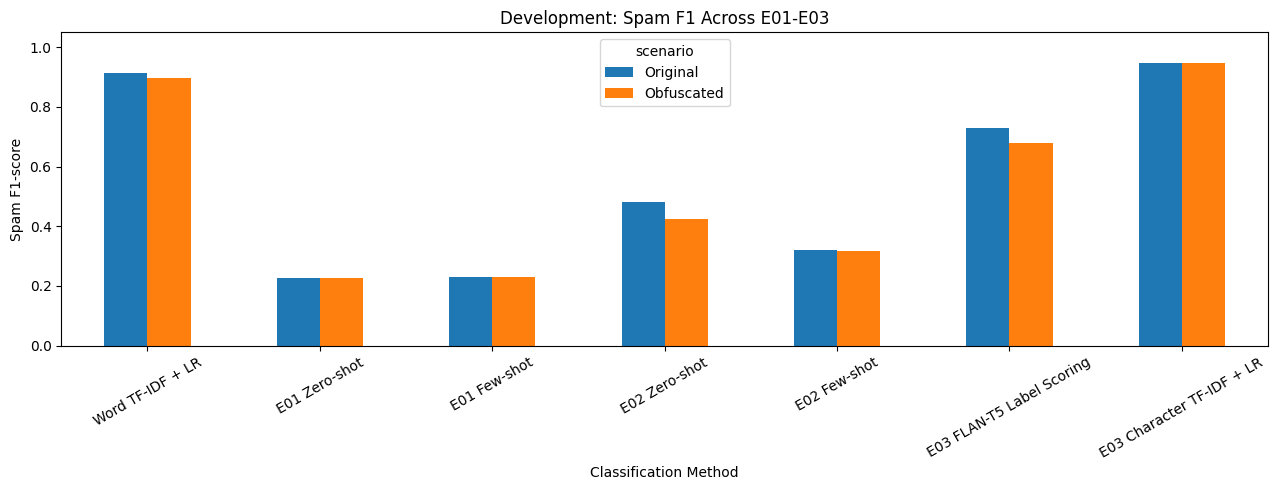

Predictions changed after obfuscation: 11


,method,actual_label,original_text,obfuscated_text,original_prediction,obfuscated_prediction
0,Word TF-IDF + LR,spam,FREE GAME. Get Rayman Golf 4 FREE from the O2 ...,fr33 GAME. Get Rayman Golf 4 fr33 from the O2 ...,spam,ham
1,E02 Zero-shot,spam,We tried to contact you re our offer of New Vi...,We tried to contact you re our 0ffer of New Vi...,spam,ham
2,E02 Zero-shot,spam,Freemsg: 1-month unlimited free calls! Activat...,Freemsg: 1-month unlimited fr33 calls! Activat...,ham,spam
3,E02 Zero-shot,ham,Text her. If she doesnt reply let me know so i...,Text her. If she doesnt r3ply let me know so i...,spam,ham
4,E02 Zero-shot,spam,Free Msg: Ringtone!From: http://tms. widelive....,fr33 Msg: Ringtone!From: http://tms. widelive....,spam,ham
5,E02 Zero-shot,spam,Congratulations U can claim 2 VIP row A Ticket...,Congratulations U can cl@im 2 VIP row A Ticket...,spam,ham
6,E02 Zero-shot,spam,Welcome! Please reply with your AGE and GENDER...,Welcome! Please r3ply with your AGE and GENDER...,spam,ham
7,E02 Zero-shot,ham,Where are you call me.,Where are you c@ll me.,ham,spam


In [11]:
# ==================================================
# CONSOLIDATE DEVELOPMENT METRICS
# ==================================================

metrics_dev = pd.concat(
    [e01_metrics, e02_metrics, e03_metrics],
    ignore_index=True
)

changed_dev = pd.concat(
    [e01_changed, e02_changed, e03_changed],
    ignore_index=True
)


# Combine predictions by matching message text
pred_dev = e01_predictions.merge(
    e02_predictions.drop(
        columns=["label", "obfuscated_text", "was_changed"]
    ),
    on="text",
    validate="one_to_one"
).merge(
    e03_predictions.drop(
        columns=["label", "obfuscated_text", "was_changed"]
    ),
    on="text",
    validate="one_to_one"
)


# Save development results
metrics_dev.to_csv(
    OUTPUT_DIR / "development_all_methods.csv",
    index=False
)

changed_dev.to_csv(
    OUTPUT_DIR / "development_changed_only.csv",
    index=False
)

pred_dev.to_csv(
    OUTPUT_DIR / "development_all_predictions.csv",
    index=False
)


print("ALL DEVELOPMENT RESULTS")

display(
    metrics_dev[
        [
            "experiment",
            "method",
            "scenario",
            "spam_precision",
            "spam_recall",
            "spam_f1"
        ]
    ].round(3)
)


# ==================================================
# DEVELOPMENT COMPARISON CHART
# ==================================================

order = [
    "Word TF-IDF + LR",
    "E01 Zero-shot",
    "E01 Few-shot",
    "E02 Zero-shot",
    "E02 Few-shot",
    "E03 FLAN-T5 Label Scoring",
    "E03 Character TF-IDF + LR"
]


plot_data = metrics_dev.pivot(
    index="method",
    columns="scenario",
    values="spam_f1"
).reindex(order)


ax = plot_data[
    ["Original", "Obfuscated"]
].plot(
    kind="bar",
    figsize=(13, 5),
    rot=30
)

ax.set_title(
    "Development: Spam F1 Across E01-E03"
)

ax.set_xlabel("Classification Method")
ax.set_ylabel("Spam F1-score")
ax.set_ylim(0, 1.05)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "development_f1_comparison.png",
    dpi=180
)

plt.show()


# ==================================================
# OBFUSCATION ERROR ANALYSIS
# ==================================================

error_rows = []

for method in order:

    safe = re.sub(
        r"[^a-zA-Z0-9]+",
        "_",
        method
    ).strip("_")

    p_orig = pred_dev[f"{safe}_Original"]
    p_obf = pred_dev[f"{safe}_Obfuscated"]

    disagreement = (
        dev_df.was_changed & p_orig.ne(p_obf)
    )

    for idx in np.flatnonzero(
        disagreement.to_numpy()
    ):

        error_rows.append({
            "method": method,
            "actual_label": dev_df.loc[idx, "label"],
            "original_text": dev_df.loc[idx, "text"],
            "obfuscated_text": dev_df.loc[idx, "obfuscated_text"],
            "original_prediction": p_orig.iloc[idx],
            "obfuscated_prediction": p_obf.iloc[idx]
        })


error_df = pd.DataFrame(
    error_rows,
    columns=[
        "method",
        "actual_label",
        "original_text",
        "obfuscated_text",
        "original_prediction",
        "obfuscated_prediction"
    ]
)


error_df.to_csv(
    OUTPUT_DIR / "obfuscation_prediction_changes.csv",
    index=False
)

print(
    "Predictions changed after obfuscation:",
    len(error_df)
)

display(error_df.head(8))

## 11. E04 — Modern SMS Evaluation

The original SMS Spam Collection is an older dataset.

Modern SMS messages include additional scenarios:

1. Personal conversations
2. Political campaign communications
3. Phishing and fraud
4. Commercial promotions

We created a small synthetic challenge set to investigate
how the models classify these message types.

### Political SMS

Political campaign messages can involve:

- Fundraising
- Event invitations
- Volunteer recruitment
- Campaign reminders

A political message is not automatically spam.

Whether it is unwanted can depend on user consent
and communication context.

### Evaluation Limitations

The 12 handcrafted messages have topic labels,
not independently verified spam/ham labels.

Therefore, this section provides qualitative analysis
rather than formal classification accuracy measurements.

In [12]:
# ==================================================
# MODERN SMS CHALLENGE SET
# ==================================================

modern_sms = pd.DataFrame([
    (
        "personal",
        "Hey, can you pick up groceries tonight?"
    ),
    (
        "personal",
        "Your appointment is confirmed for Thursday."
    ),
    (
        "political",
        "Hello, this is the campaign volunteer team. "
        "Our town hall is next week."
    ),
    (
        "political",
        "Campaign update: Would you like to volunteer this weekend?"
    ),
    (
        "political",
        "Urgent campaign fundraising deadline tonight. "
        "Please consider donating."
    ),
    (
        "political",
        "Thank you for signing up for campaign event reminders."
    ),
    (
        "phishing",
        "Unpaid toll detected. Enter your payment details immediately."
    ),
    (
        "phishing",
        "Your bank account is locked. "
        "Verify your identity using this link."
    ),
    (
        "phishing",
        "We cannot process your donation. "
        "Reply with your credit card number."
    ),
    (
        "commercial",
        "Limited time! Get 50 percent off your next purchase."
    ),
    (
        "commercial",
        "Exclusive offer for new customers. Sign up today."
    ),
    (
        "commercial",
        "Congratulations! Claim your free gift card now."
    )
], columns=["topic", "text"])


# ==================================================
# APPLY ALL FIVE CLASSIFICATION METHODS
# ==================================================

MODERN_METHODS = [
    (
        "Word TF-IDF + LR",
        lambda x: predict_classical(x, word_model)
    ),
    (
        "E02 Zero-shot",
        lambda x: predict_generated(
            x, build_prompt_e02, "Zero-shot"
        )
    ),
    (
        "E02 Few-shot",
        lambda x: predict_generated(
            x, build_prompt_e02, "Few-shot"
        )
    ),
    (
        "E03 FLAN-T5 Label Scoring",
        predict_label_scoring
    ),
    (
        "E03 Character TF-IDF + LR",
        lambda x: predict_classical(x, char_model)
    )
]


for name, predictor in MODERN_METHODS:

    print("Classifying modern messages:", name)

    predictions, _, _ = predictor(
        modern_sms.text.tolist()
    )

    modern_sms[name] = predictions


# ==================================================
# SAVE RESULTS
# ==================================================

modern_sms.to_csv(
    OUTPUT_DIR / "e04_modern_sms_case_study.csv",
    index=False
)

display(modern_sms)

print(
    "Note: Topic labels are not verified binary spam labels."
)

Classifying modern messages: Word TF-IDF + LR
Classifying modern messages: E02 Zero-shot
Classifying modern messages: E02 Few-shot
Classifying modern messages: E03 FLAN-T5 Label Scoring
Classifying modern messages: E03 Character TF-IDF + LR


,topic,text,Word TF-IDF + LR,E02 Zero-shot,E02 Few-shot,E03 FLAN-T5 Label Scoring,E03 Character TF-IDF + LR
0,personal,"Hey, can you pick up groceries tonight?",ham,ham,ham,ham,ham
1,personal,Your appointment is confirmed for Thursday.,ham,ham,ham,ham,ham
2,political,"Hello, this is the campaign volunteer team. Ou...",spam,ham,spam,ham,ham
3,political,Campaign update: Would you like to volunteer t...,ham,spam,spam,ham,ham
4,political,Urgent campaign fundraising deadline tonight. ...,ham,spam,spam,spam,ham
5,political,Thank you for signing up for campaign event re...,ham,spam,spam,ham,ham
6,phishing,Unpaid toll detected. Enter your payment detai...,ham,spam,spam,ham,ham
7,phishing,Your bank account is locked. Verify your ident...,spam,spam,spam,ham,ham
8,phishing,We cannot process your donation. Reply with yo...,spam,spam,spam,spam,spam
9,commercial,Limited time! Get 50 percent off your next pur...,spam,spam,spam,ham,ham


Note: Topic labels are not verified binary spam labels.


## 12. E05 — Final Unseen Evaluation

Our previous experiments evaluated the same 240 messages.

Repeatedly examining that development sample can influence
how we design the classification methods.

To evaluate generalization, E05 tests the finalized models
on a separate set of previously unseen messages.

### Evaluation Rules

- Do not retrain the classifiers using E05 messages.
- Do not modify prompts based on E05 results.
- Use the same model configurations from E02 and E03.
- Evaluate both original and obfuscated messages.

### Models

1. Word TF-IDF + Logistic Regression
2. FLAN-T5 Zero-shot (E02)
3. FLAN-T5 Few-shot (E02)
4. FLAN-T5 Candidate-Label Scoring (E03)
5. Character TF-IDF + Logistic Regression (E03)

The default final evaluation contains 300 messages.

The full remaining holdout pool contains 1,050 messages.

To evaluate the entire pool, set FINAL_SAMPLES = None
in the configuration cell before running this notebook.

E05 represents the independent final evaluation.

In [13]:
# ==================================================
# E05 - FINAL HELD-OUT EVALUATION
# ==================================================

E05_METHODS = [
    (
        "E05",
        "Word TF-IDF + LR",
        lambda msgs: predict_classical(
            msgs, word_model
        )
    ),
    (
        "E05",
        "E02 Zero-shot",
        lambda msgs: predict_generated(
            msgs, build_prompt_e02, "Zero-shot"
        )
    ),
    (
        "E05",
        "E02 Few-shot",
        lambda msgs: predict_generated(
            msgs, build_prompt_e02, "Few-shot"
        )
    ),
    (
        "E05",
        "E03 FLAN-T5 Label Scoring",
        predict_label_scoring
    ),
    (
        "E05",
        "E03 Character TF-IDF + LR",
        lambda msgs: predict_classical(
            msgs, char_model
        )
    )
]


# Evaluate on the independent final dataset
e05_metrics, e05_changed, e05_predictions = (
    evaluate_methods(final_df, E05_METHODS)
)


# Save all results
save_experiment(
    "e05_final_holdout",
    e05_metrics,
    e05_changed,
    e05_predictions
)


print("\nFINAL UNSEEN EVALUATION RESULTS")

display(
    e05_metrics[
        [
            "method",
            "scenario",
            "n",
            "accuracy",
            "spam_precision",
            "spam_recall",
            "spam_f1"
        ]
    ].round(3)
)

Evaluating: Word TF-IDF + LR
Evaluating: E02 Zero-shot
Evaluating: E02 Few-shot
Evaluating: E03 FLAN-T5 Label Scoring
Evaluating: E03 Character TF-IDF + LR

FINAL UNSEEN EVALUATION RESULTS


,method,scenario,n,accuracy,spam_precision,spam_recall,spam_f1
0,Word TF-IDF + LR,Original,300,0.980,0.878,0.973,0.923
1,Word TF-IDF + LR,Obfuscated,300,0.987,0.946,0.946,0.946
2,E02 Zero-shot,Original,300,0.883,0.518,0.784,0.624
3,E02 Zero-shot,Obfuscated,300,0.867,0.472,0.676,0.556
4,E02 Few-shot,Original,300,0.540,0.211,1.000,0.349
5,E02 Few-shot,Obfuscated,300,0.537,0.210,1.000,0.347
6,E03 FLAN-T5 Label Scoring,Original,300,0.953,0.926,0.676,0.781
7,E03 FLAN-T5 Label Scoring,Obfuscated,300,0.940,0.913,0.568,0.700
8,E03 Character TF-IDF + LR,Original,300,0.983,0.921,0.946,0.933
9,E03 Character TF-IDF + LR,Obfuscated,300,0.983,0.971,0.892,0.930


## 13. Final Comparative Evaluation

We compare development-stage performance against
performance on unseen messages.

### Main Evaluation Metric

Spam F1-score is the primary metric because the
dataset contains substantially more ham than spam.

Additional metrics include:

- Accuracy
- Spam precision
- Spam recall
- False positives
- False negatives

### Visualizations

1. Development vs final evaluation F1-scores
2. Confusion matrices for the five classifiers
3. Final model ranking

The E05 evaluation is our primary evidence of
performance on unseen messages.

Development-stage results explain the evolution
of the project and the effects of each modification.

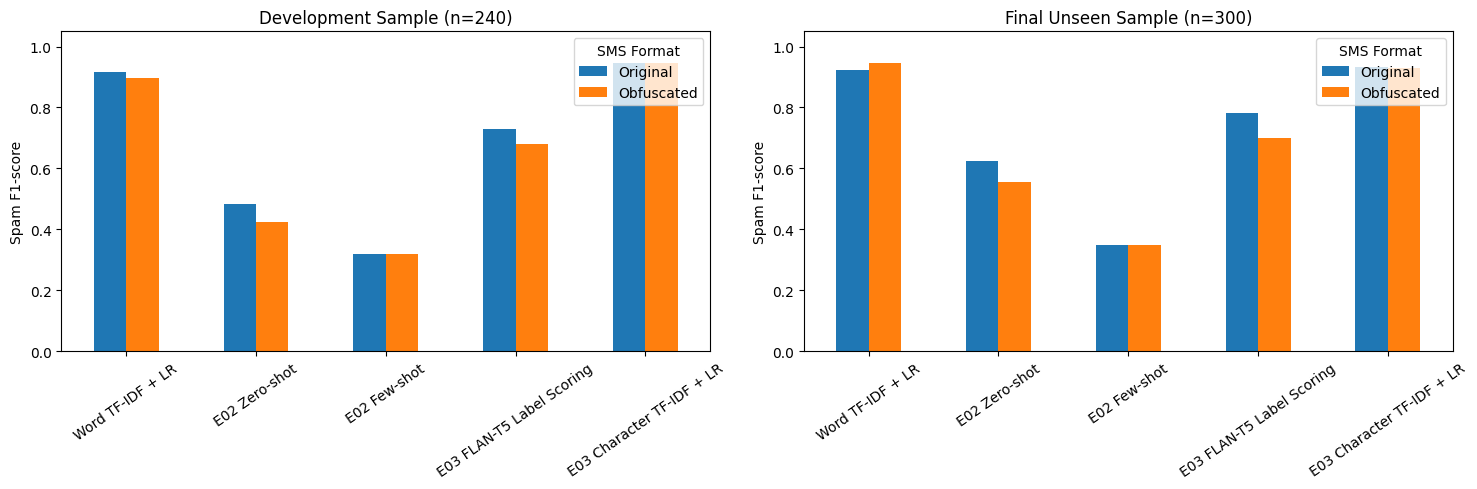

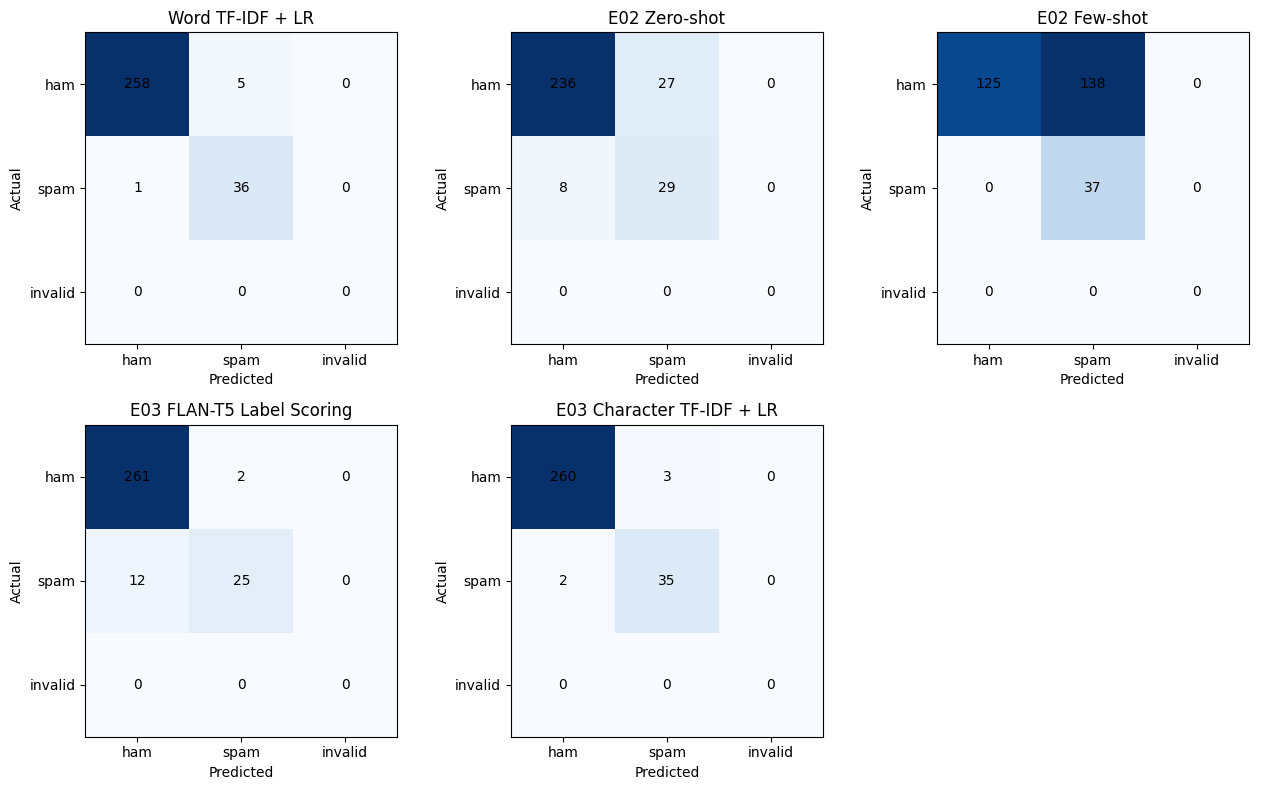

FINAL MODEL RANKING - ORIGINAL SMS


,method,accuracy,spam_precision,spam_recall,spam_f1
8,E03 Character TF-IDF + LR,0.983,0.921,0.946,0.933
0,Word TF-IDF + LR,0.980,0.878,0.973,0.923
6,E03 FLAN-T5 Label Scoring,0.953,0.926,0.676,0.781
2,E02 Zero-shot,0.883,0.518,0.784,0.624
4,E02 Few-shot,0.540,0.211,1.000,0.349


In [14]:
# ==================================================
# COMPARE DEVELOPMENT AND FINAL EVALUATION
# ==================================================

main_order = [
    "Word TF-IDF + LR",
    "E02 Zero-shot",
    "E02 Few-shot",
    "E03 FLAN-T5 Label Scoring",
    "E03 Character TF-IDF + LR"
]


fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)


for ax, table, title in [
    (
        axes[0],
        metrics_dev,
        f"Development Sample (n={len(dev_df)})"
    ),
    (
        axes[1],
        e05_metrics,
        f"Final Unseen Sample (n={len(final_df)})"
    )
]:

    wide = table[
        table.method.isin(main_order)
    ].pivot(
        index="method",
        columns="scenario",
        values="spam_f1"
    ).reindex(main_order)

    wide[
        ["Original", "Obfuscated"]
    ].plot(
        kind="bar",
        ax=ax,
        rot=35
    )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Spam F1-score")
    ax.set_ylim(0, 1.05)

    ax.legend(
        title="SMS Format",
        loc="upper right"
    )


plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "development_vs_final_f1.png",
    dpi=180
)

plt.show()


# ==================================================
# CONFUSION MATRICES FOR FINAL EVALUATION
# ==================================================

fig, axs = plt.subplots(
    2,
    3,
    figsize=(13, 8)
)

axs = axs.flatten()


for ax, method in zip(axs, main_order):

    safe = re.sub(
        r"[^a-zA-Z0-9]+",
        "_",
        method
    ).strip("_")

    pred = e05_predictions[
        f"{safe}_Original"
    ]

    label_names = [
        "ham",
        "spam",
        "invalid"
    ]

    cm = confusion_matrix(
        final_df.label,
        pred,
        labels=label_names
    )

    ax.imshow(
        cm,
        cmap="Blues"
    )

    for i in range(3):

        for j in range(3):

            ax.text(
                j,
                i,
                str(cm[i, j]),
                ha="center",
                va="center"
            )

    ax.set_xticks(
        range(3),
        labels=label_names
    )

    ax.set_yticks(
        range(3),
        labels=label_names
    )

    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(method)


axs[-1].axis("off")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "e05_confusion_matrices.png",
    dpi=180
)

plt.show()


# ==================================================
# FINAL MODEL RANKING
# ==================================================

print("FINAL MODEL RANKING - ORIGINAL SMS")

display(
    e05_metrics[
        e05_metrics.scenario == "Original"
    ].sort_values(
        "spam_f1",
        ascending=False
    )[
        [
            "method",
            "accuracy",
            "spam_precision",
            "spam_recall",
            "spam_f1"
        ]
    ].round(3)
)

## 14. Live SMS Classification Demo

This section demonstrates how the five classification
methods handle an individual SMS message.

The input text can be modified during the classroom
presentation to demonstrate model behavior.

Example messages:

- "Hey, are we still meeting tonight?"
- "URG3NT! Cl@im your fr33 prize now!"
- "Your package could not be delivered. Verify payment."
- "Thank you for registering for our campaign event."

The demo does not modify training or evaluation data.

Avoid entering private SMS messages into a publicly
shared notebook.

In [15]:
# ==================================================
# LIVE SMS DEMONSTRATION
# ==================================================

DEMO_MESSAGE = "URG3NT! Cl@im your fr33 prize now!"

print("SMS Message:")
print(DEMO_MESSAGE)

print("\nClassification Results:")


for name, predictor in MODERN_METHODS:

    pred, _, seconds = predictor(
        [DEMO_MESSAGE]
    )

    print(
        f"{name:30s}: {pred[0]}"
    )

SMS Message:
URG3NT! Cl@im your fr33 prize now!

Classification Results:
Word TF-IDF + LR              : spam
E02 Zero-shot                 : spam
E02 Few-shot                  : spam
E03 FLAN-T5 Label Scoring     : spam
E03 Character TF-IDF + LR     : spam


## 15. Conclusion and Future Work

This project investigates how different text representations
and language model classification strategies affect SMS
spam detection.

### Major Research Topics

1. Traditional machine learning versus instruction-tuned LLMs
2. Original versus improved prompt engineering
3. Free-form text generation versus candidate-label scoring
4. Word-level versus character-level TF-IDF
5. Classification robustness to keyword obfuscation
6. Generalization to unseen messages
7. Modern SMS examples, including political outreach

### Questions to Answer in the Final Report

- Which model achieved the highest spam F1-score on E05?
- Did E03 improvements generalize to unseen messages?
- Did obfuscation reduce classification performance?
- Which models generated the most false positives?
- Which models missed the most spam?
- What happened when models classified political messages?

### Limitations

- The dataset contains older English-language SMS messages.
- The dataset contains substantially more ham than spam.
- Only one pretrained language model is evaluated.
- No language model fine-tuning is performed.
- Obfuscation uses a limited set of substitutions.
- E04 contains 12 synthetic examples without verified spam labels.
- Public training datasets may have appeared during LLM pretraining.
- Results may vary with library and model versions.

### Future Work

- Evaluate additional pretrained language models.
- Investigate supervised fine-tuning.
- Collect contemporary SMS examples with verified labels.
- Expand the political-message evaluation.
- Test multilingual SMS spam.
- Investigate model confidence and uncertainty.

Final conclusions must be based on the measured experimental
results rather than assumed model performance.

## Historical Experiment Results

This section preserves the key numerical results
from earlier Colab executions.

Historical results are provided for comparison with
the newly executed notebook.

They are not substituted for new model predictions.

### Earlier Findings

- E01 demonstrated poor initial FLAN-T5 performance.
- E02 improved prompt engineering.
- E03 improved classification using candidate-label
  scoring and character-level text representations.

The historical data will help document the development
of the project in the final report and presentation.

In [16]:
# ==================================================
# HISTORICAL RESULTS FROM PREVIOUS COLAB RUNS
# ==================================================

# Columns:
# Experiment, Method, Scenario, Accuracy, Spam F1

historical_data = [
    ("E01", "Word TF-IDF + LR", "Original", 0.9792, 0.9153),
    ("E01", "Word TF-IDF + LR", "Obfuscated", 0.9750, 0.8966),
    ("E01", "Zero-shot", "Original", 0.1500, 0.2273),
    ("E01", "Zero-shot", "Obfuscated", 0.1500, 0.2273),
    ("E01", "Few-shot", "Original", 0.1625, 0.2299),
    ("E01", "Few-shot", "Obfuscated", 0.1625, 0.2299),

    ("E02", "Word TF-IDF + LR", "Original", 0.9792, 0.9153),
    ("E02", "Word TF-IDF + LR", "Obfuscated", 0.9750, 0.8966),
    ("E02", "Zero-shot", "Original", 0.8208, 0.4819),
    ("E02", "Zero-shot", "Obfuscated", 0.8083, 0.4250),
    ("E02", "Few-shot", "Original", 0.4667, 0.3191),
    ("E02", "Few-shot", "Obfuscated", 0.4625, 0.3175),

    ("E03", "FLAN-T5 Label Scoring", "Original", 0.9417, 0.7308),
    ("E03", "FLAN-T5 Label Scoring", "Obfuscated", 0.9333, 0.6800),
    ("E03", "Character TF-IDF + LR", "Original", 0.9875, 0.9474),
    ("E03", "Character TF-IDF + LR", "Obfuscated", 0.9875, 0.9474)
]


historical_results = pd.DataFrame(
    historical_data,
    columns=[
        "experiment",
        "method",
        "scenario",
        "accuracy",
        "spam_f1"
    ]
)

historical_results["source"] = "Previous Colab execution"

historical_results["n"] = 240


# Save historical measurements
historical_results.to_csv(
    OUTPUT_DIR / "historical_experiment_results.csv",
    index=False
)

print("Historical experiment results:")

display(historical_results)

Historical experiment results:


,experiment,method,scenario,accuracy,spam_f1,source,n
0,E01,Word TF-IDF + LR,Original,0.9792,0.9153,Previous Colab execution,240
1,E01,Word TF-IDF + LR,Obfuscated,0.9750,0.8966,Previous Colab execution,240
2,E01,Zero-shot,Original,0.1500,0.2273,Previous Colab execution,240
3,E01,Zero-shot,Obfuscated,0.1500,0.2273,Previous Colab execution,240
4,E01,Few-shot,Original,0.1625,0.2299,Previous Colab execution,240
5,E01,Few-shot,Obfuscated,0.1625,0.2299,Previous Colab execution,240
6,E02,Word TF-IDF + LR,Original,0.9792,0.9153,Previous Colab execution,240
7,E02,Word TF-IDF + LR,Obfuscated,0.9750,0.8966,Previous Colab execution,240
8,E02,Zero-shot,Original,0.8208,0.4819,Previous Colab execution,240
9,E02,Zero-shot,Obfuscated,0.8083,0.4250,Previous Colab execution,240


## 16. Consolidated Results Export

All experiments save their outputs into one folder.

The final ZIP package includes:

- E01 initial evaluation results
- E02 improved prompting results
- E03 alternative classification results
- E04 modern SMS case study
- E05 unseen evaluation
- Development comparison charts
- Final confusion matrices
- Individual message predictions
- Historical experiment results
- Experimental configuration and summary

Only one ZIP archive is created and downloaded.

No additional export cells are needed.

In [17]:
# ==================================================
# FINAL CONSOLIDATED RESULTS EXPORT
# ==================================================

# --------------------------------------------------
# 1. Project configuration
# --------------------------------------------------

manifest = {
    "project": "SMS Spam Detection - AI Course Project",

    "model": MODEL_NAME,

    "seed": SEED,

    "python": sys.version.split()[0],

    "pytorch": torch.__version__,

    "training_count": len(train_df),

    "development_count": len(dev_df),

    "e05_holdout_count": len(final_df),

    "e05_candidate_pool_size": len(e05_pool),

    "development_changed_count": int(
        dev_df.was_changed.sum()
    ),

    "e05_changed_count": int(
        final_df.was_changed.sum()
    ),

    "e04_note": (
        "12 synthetic topic-labeled messages; "
        "qualitative analysis only"
    ),

    "evaluation_note": (
        "E05 is separate from training and development"
    ),

    "runtime_note": (
        "Obfuscated inference time measures incremental "
        "changed-message processing"
    ),

    "classification_methods": main_order
}


# --------------------------------------------------
# 2. Save experiment configuration
# --------------------------------------------------

(OUTPUT_DIR / "manifest.json").write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8"
)


# --------------------------------------------------
# 3. Create readable experiment summary
# --------------------------------------------------

summary = [
    "SMS SPAM DETECTION - AI SEMESTER PROJECT",
    "",
    "PROJECT CONFIGURATION",
    json.dumps(manifest, indent=2),
    "",
    "DEVELOPMENT RESULTS",
    metrics_dev.round(4).to_string(index=False),
    "",
    "E05 FINAL HOLDOUT RESULTS",
    e05_metrics.round(4).to_string(index=False),
    "",
    "IMPORTANT NOTES",
    "E04 contains synthetic messages without binary spam ground truth.",
    "E05 should not be used for further prompt tuning.",
    "Historical results are separate from newly generated measurements."
]


(OUTPUT_DIR / "RESULTS_README.txt").write_text(
    "\n".join(summary),
    encoding="utf-8"
)


# --------------------------------------------------
# 4. Display saved files
# --------------------------------------------------

print("\nSAVED EXPERIMENT FILES")

for file in sorted(OUTPUT_DIR.iterdir()):

    if file.is_file():
        print("-", file.name)


# --------------------------------------------------
# 5. Generate versioned ZIP archive
# --------------------------------------------------

from pathlib import Path
from shutil import make_archive
import re

BASE_NAME = "SMS_Spam_Project_Complete_Results"

# Find existing versions in the Colab working directory
existing_versions = []

for file in Path(".").glob(f"{BASE_NAME}_v*.zip"):

    match = re.fullmatch(
        rf"{re.escape(BASE_NAME)}_v(\d+)\.zip",
        file.name
    )

    if match:
        existing_versions.append(int(match.group(1)))

# Increment version
next_version = max(existing_versions, default=0) + 1

archive_name = f"{BASE_NAME}_v{next_version:03d}"

# Record version in the results manifest
manifest["archive_version"] = next_version
manifest["archive_filename"] = archive_name + ".zip"

(OUTPUT_DIR / "manifest.json").write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8"
)

# Create one versioned ZIP
archive_path = make_archive(
    archive_name,
    "zip",
    root_dir=".",
    base_dir=str(OUTPUT_DIR)
)

print(f"Version: v{next_version:03d}")
print(f"Created: {archive_path}")


# --------------------------------------------------
# 6. Download versioned ZIP archive
# --------------------------------------------------

try:
    from google.colab import files

    files.download(archive_path)

except ImportError:
    print("Archive saved locally:", archive_path)


SAVED EXPERIMENT FILES
- RESULTS_README.txt
- development_all_methods.csv
- development_all_predictions.csv
- development_changed_only.csv
- development_f1_comparison.png
- development_vs_final_f1.png
- e01_changed_only_metrics.csv
- e01_metrics.csv
- e01_predictions.csv
- e02_changed_only_metrics.csv
- e02_metrics.csv
- e02_predictions.csv
- e03_changed_only_metrics.csv
- e03_metrics.csv
- e03_predictions.csv
- e04_modern_sms_case_study.csv
- e05_confusion_matrices.png
- e05_final_holdout_changed_only_metrics.csv
- e05_final_holdout_metrics.csv
- e05_final_holdout_predictions.csv
- historical_experiment_results.csv
- manifest.json
- obfuscation_prediction_changes.csv

One consolidated ZIP created:
/content/SMS_Spam_Project_Complete_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 17. References and Citations

1. Almeida, T. A., Hidalgo, J. M. G., & Yamakami, A. (2011).
   Contributions to the Study of SMS Spam Filtering:
   New Collection and Results.
   ACM Symposium on Document Engineering.
   https://archive.ics.uci.edu/dataset/228/sms+spam+collection

2. Chung, H. W., et al. (2022).
   Scaling Instruction-Finetuned Language Models.
   https://arxiv.org/abs/2210.11416

3. Google.
   FLAN-T5-base Model Card.
   https://huggingface.co/google/flan-t5-base

4. Pedregosa, F., et al. (2011).
   Scikit-learn: Machine Learning in Python.
   Journal of Machine Learning Research, 12, 2825–2830.
   https://jmlr.csail.mit.edu/papers/v12/pedregosa11a.html

5. Hugging Face.
   Transformers Documentation.
   https://huggingface.co/docs/transformers/index

### Acknowledgments

This project uses publicly available research datasets,
open-source machine learning libraries, and pretrained
language models.

The experimental implementation and evaluation build
upon these resources.

All external sources and assistance should be acknowledged
according to the course's academic integrity requirements.